# 대형 Steam 리뷰 원본 두 개와 frank 평가셋의 조합 EDA

artermiloff 2024 v1과 Kieran v2 원본을 각각 학습 자료로 검토한다.
**최종 판정: Kieran 원본 → frank만 권장한다.** artermiloff 원본은
정수처럼 보이는 Steam ID 자체에 float64 반올림 손실이 있어 사용에서 제외한다.
Kieran에서는 frank 평가 후보 계정 87,573명을 통째로 제외하고,
남은 계정 중 공통 Steam ID 해시 규칙으로 약 10%를 검증용으로 예약한다.
이 노트북은 전체 원본에서 계산한 집계 JSON을 읽으며 모델을 학습하지 않는다.
사용자별 데이터, 최종 입력/정답 파일, 추천 성능은 출력하지 않는다.

**해석 범위:** 입력은 기존 A에 리뷰가 있는 게임, 정답은 그중 A의 공식 Linux
게임으로 고정한다. A의 상호작용을 새 학습 자료에 섞지 않는다.
적격 사용자 수는 긍정 정답 하나를 숨긴 뒤 서로 다른 입력 게임이 최소 k개
남을 수 있는 잠재 규모다. 실제 정답 선택이나 성능 측정 결과가 아니다.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

EDA = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (EDA / "reports").exists():
    EDA = EDA / "EDA"
sys.path.insert(0, str(EDA / "scripts"))
from readable_labels import setup_korean_font

assert setup_korean_font(), "한글 글꼴이 필요합니다."
plt.rcParams.update({"figure.facecolor":"white","axes.spines.top":False,
                     "axes.spines.right":False,"axes.grid":True,"grid.alpha":0.2,
                     "axes.axisbelow":True,"font.size":10})
SOURCES = {"artermiloff_2024":"artermiloff (ID 손상)", "kieran_original":"Kieran 원본"}
COLORS = ["#2463a6", "#da7732"]
metrics = {name:json.loads((EDA / "reports" / f"{name}_frank_eda_metrics.json").read_text("utf-8"))
           for name in SOURCES}
for m in metrics.values():
    assert m["scope"].startswith("Complete")
    assert m["frank_provenance"]["reserved_test_users"] == 87573
    assert all(v == 0 for v in m["post_exclusion_checks"].values()), "계정/리뷰 분리 검사 실패"
assert metrics["kieran_original"]["whole_account_and_cross_review_identity_checks_passed"]
assert not metrics["artermiloff_2024"]["whole_account_and_cross_review_identity_checks_passed"]
precision=json.loads((EDA/"reports/original_identity_precision_metrics.json").read_text("utf-8"))
display(pd.DataFrame([{
    "원본 ID가 모두 16의 배수인 행":precision["whole_source_residues"]["author_ids_divisible_by_16"],
    "동일 원 리뷰의 실제 계정과 다른 ID":precision["distinct_matched_review_ids"]["different_author_original_review_ids"],
    "검증 예약 후에도 남은 실제 평가 계정 리뷰":precision["known_test_accounts_left_in_naive_artermiloff_preview"]["known_test_account_review_ids_remaining_after_validation"]}]))
print("artermiloff의 명목상 ID 교집합 0은 독립성 보장이 아닙니다. 이 원본은 학습·평가에서 제외합니다.")

,원본 ID가 모두 16의 배수인 행,동일 원 리뷰의 실제 계정과 다른 ID,검증 예약 후에도 남은 실제 평가 계정 리뷰
0,127572734,1190538,2344585


artermiloff의 명목상 ID 교집합 0은 독립성 보장이 아닙니다. 이 원본은 학습·평가에서 제외합니다.


## 1. 전체 원본의 규모와 정리 결과

원본 ID는 문자열로 읽고, 분석 엔진 안에서는 손실 없는 64비트 정수로 비교한다.
사용자/App ID가 충돌하는 원 리뷰 ID와 긍정·부정이 충돌하는 사용자–게임 쌍은
격리한다. 아래 수치는 최종 모델 학습용 파일을 생성한 결과가 아니다.

In [2]:
summary = []
for key,label in SOURCES.items():
    m=metrics[key]
    s,p,t=m["clean_source"],m["after_test_exclusion"],m["after_validation_reservation"]
    valid=m["whole_account_and_cross_review_identity_checks_passed"]
    summary.append({"학습 후보":label,"원본 행":m["raw_quality"]["raw_rows"],
                    "판정":"사용 가능" if valid else "사용 제외: 원본 ID 손상",
                    "정리 후 리뷰 쌍":s["pairs"] if valid else None,"정리 후 사용자":s["users"] if valid else None,
                    "게임":s["apps"],"긍정 비율":s["positives"]/s["pairs"],
                    "평가 계정 제외 리뷰 쌍":p["removed_test_pairs"] if valid else None,
                    "평가 제외 후 학습 쌍":p["pairs"] if valid else None,
                    "검증 예약 후 학습 쌍":t["pairs"] if valid else None,
                    "검증 예약 후 Linux 게임":t["linux_apps_in_fixed_catalog"] if valid else None})
summary=pd.DataFrame(summary)
summary.to_csv(EDA/"reports/tables/16_large_original_comparison.csv",index=False,encoding="utf-8-sig")
display(summary)

,학습 후보,원본 행,판정,정리 후 리뷰 쌍,정리 후 사용자,게임,긍정 비율,평가 계정 제외 리뷰 쌍,평가 제외 후 학습 쌍,검증 예약 후 학습 쌍,검증 예약 후 Linux 게임
0,artermiloff (ID 손상),127572881,사용 제외: 원본 ID 손상,NaN,NaN,79184,0.859346,NaN,NaN,NaN,NaN
1,Kieran 원본,113883717,사용 가능,113195034.0,37875512.0,105838,0.855967,3360025.0,109835009.0,98857701.0,6603.0


In [3]:
quality=[]
histories=[]
for key,label in SOURCES.items():
    m=metrics[key]
    q,s=m["raw_quality"],m["clean_source"]
    quality.append({"학습 후보":label,"식별자·라벨 격리 행":q["quarantined_rows"],
                    "원 리뷰 소유자 충돌":q["review_ids_with_conflicting_owner"],
                    "App ID 충돌 원 리뷰":q["review_ids_with_conflicting_app"],
                    "자료간 모호성 추가 격리 리뷰":q["additional_cross_source_review_ids_quarantined"],
                    "같은 라벨 반복 행":q["same_label_duplicate_rows"],
                    "긍정·부정 충돌 쌍":q["conflicting_label_pairs"],
                    "최초 작성 시각 결측·형식 오류":q["missing_created_times"],
                    "갱신이 작성보다 이른 행":q["updated_before_created"]})
    h=s["history_quantiles"]
    if not m["whole_account_and_cross_review_identity_checks_passed"]:
        continue
    histories.append({"학습 후보":label,"게임 1개만 리뷰한 사용자":s["single_game_users"],
                      "사용자별 게임 수 중앙값":h[1],"사용자별 게임 수 p90":h[3],
                      "사용자별 게임 수 p99":h[4],"최대 리뷰 게임 수":h[5],
                      "게임당 리뷰 수 중앙값":s["app_review_quantiles"][1],
                      "상위 50게임 리뷰 비중":s["top_50_review_share"]})
display(pd.DataFrame(quality))
display(pd.DataFrame(histories))

,학습 후보,식별자·라벨 격리 행,원 리뷰 소유자 충돌,App ID 충돌 원 리뷰,자료간 모호성 추가 격리 리뷰,같은 라벨 반복 행,긍정·부정 충돌 쌍,최초 작성 시각 결측·형식 오류,갱신이 작성보다 이른 행
0,artermiloff (ID 손상),147,0,173149,1190418,0,0,0,97
1,Kieran 원본,0,0,332865,3,2375,72,0,2


,학습 후보,게임 1개만 리뷰한 사용자,사용자별 게임 수 중앙값,사용자별 게임 수 p90,사용자별 게임 수 p99,최대 리뷰 게임 수,게임당 리뷰 수 중앙값,상위 50게임 리뷰 비중
0,Kieran 원본,20900389,1,6,25,9807,16,0.323052


## 2. 원 계정·원 리뷰 중복과 제외 후 검사

서로 다른 배포 파일이어도 원 계정과 원 리뷰가 겹칠 수 있다.
같은 계정의 모든 게임을 제외하며, 정답 리뷰만 지우지 않는다.
두 학습 후보를 합치는 실험은 수행하지 않았고 둘 사이 중복도 별도 문제다.

In [4]:
overlap=[]
for key,label in SOURCES.items():
    m=metrics[key]
    o=m["cross_source_overlap"]
    overlap.append({"학습 후보":label,"frank와 같은 저장 ID(실계정 검증 별도)":o["common_clean_steam_users"],
                    "공통 원 리뷰":o["common_original_review_ids"],
                    "정리 전 공통 리뷰 소유자·게임 불일치":o["common_review_ids_with_different_user_or_app"],
                    "정리 후 공통 리뷰 소유자·게임 불일치":o["retained_clean_review_ids_with_incompatible_owner_or_app"],
                    "공통 원 리뷰 라벨 변경":o["common_review_ids_with_changed_label"],
                    **m["post_exclusion_checks"]})
display(pd.DataFrame(overlap).rename(columns={
    "remaining_train_test_user_intersection":"제외 후 공통 계정",
    "remaining_train_test_user_app_intersection":"제외 후 공통 사용자–게임",
    "remaining_train_test_original_review_id_intersection":"제외 후 공통 원 리뷰"}))

,학습 후보,frank와 같은 저장 ID(실계정 검증 별도),공통 원 리뷰,정리 전 공통 리뷰 소유자·게임 불일치,정리 후 공통 리뷰 소유자·게임 불일치,공통 원 리뷰 라벨 변경,제외 후 공통 계정,제외 후 공통 사용자–게임,제외 후 공통 원 리뷰
0,artermiloff (ID 손상),73857,1270339,1190553,0,868,0,0,0
1,Kieran 원본,1045364,1089913,185,0,12600,0,0,0


## 3. 학습 근거와 평가 가능 범위 비교

아이템 지원 수는 그 게임을 리뷰한 서로 다른 학습 계정 수다.
긍정 지원 수가 충분해도 입력 게임과 정답 게임의 공동 긍정 이웃이 존재한다는
뜻은 아니다. 여기서는 Item-KNN 연결성이나 추천 정확도를 인증하지 않는다.
입력 최소 수별 집계는 같은 평가 후보 계정 집합 안에서 계산한다.

In [5]:
common=json.loads((EDA/"reports/large_original_frank_comparison_metrics.json").read_text("utf-8"))
diagnostics=[]
for name,label in [("fixed_A_reviewed_catalog","고정 평가 범위"),
                    ("safe_mapping_fixed_catalog","App ID 모호 리뷰를 제거한 평가 범위"),
                    ("safe_mapping_kieran_review_support","정리 후 Kieran 학습 리뷰 존재"),
                    ("safe_mapping_kieran_positive_support_5","정리 후 Kieran 긍정 사용자 ≥5")]:
    row=next(r for r in common["cohorts"][name] if r["minimum_inputs"]==5)
    diagnostics.append({"조건":label,"입력 ≥5 잠재 사용자":row["potential_users"],
                        "숨김 후 긍정 입력도 있는 사용자":row["potential_users_with_positive_query"],
                        "숨김 후 부정 입력만 남는 사용자":row["potential_users_with_only_negative_query"]})
display(pd.DataFrame(diagnostics))
print("지원 범위는 진단값입니다. 기본 평가 명단에서 지원이 적은 사용자를 모델마다 제거하지 않습니다.")

,조건,입력 ≥5 잠재 사용자,숨김 후 긍정 입력도 있는 사용자,숨김 후 부정 입력만 남는 사용자
0,고정 평가 범위,24577,24348,229
1,App ID 모호 리뷰를 제거한 평가 범위,24571,24342,229
2,정리 후 Kieran 학습 리뷰 존재,24479,24250,229
3,정리 후 Kieran 긍정 사용자 ≥5,24339,24108,231


지원 범위는 진단값입니다. 기본 평가 명단에서 지원이 적은 사용자를 모델마다 제거하지 않습니다.


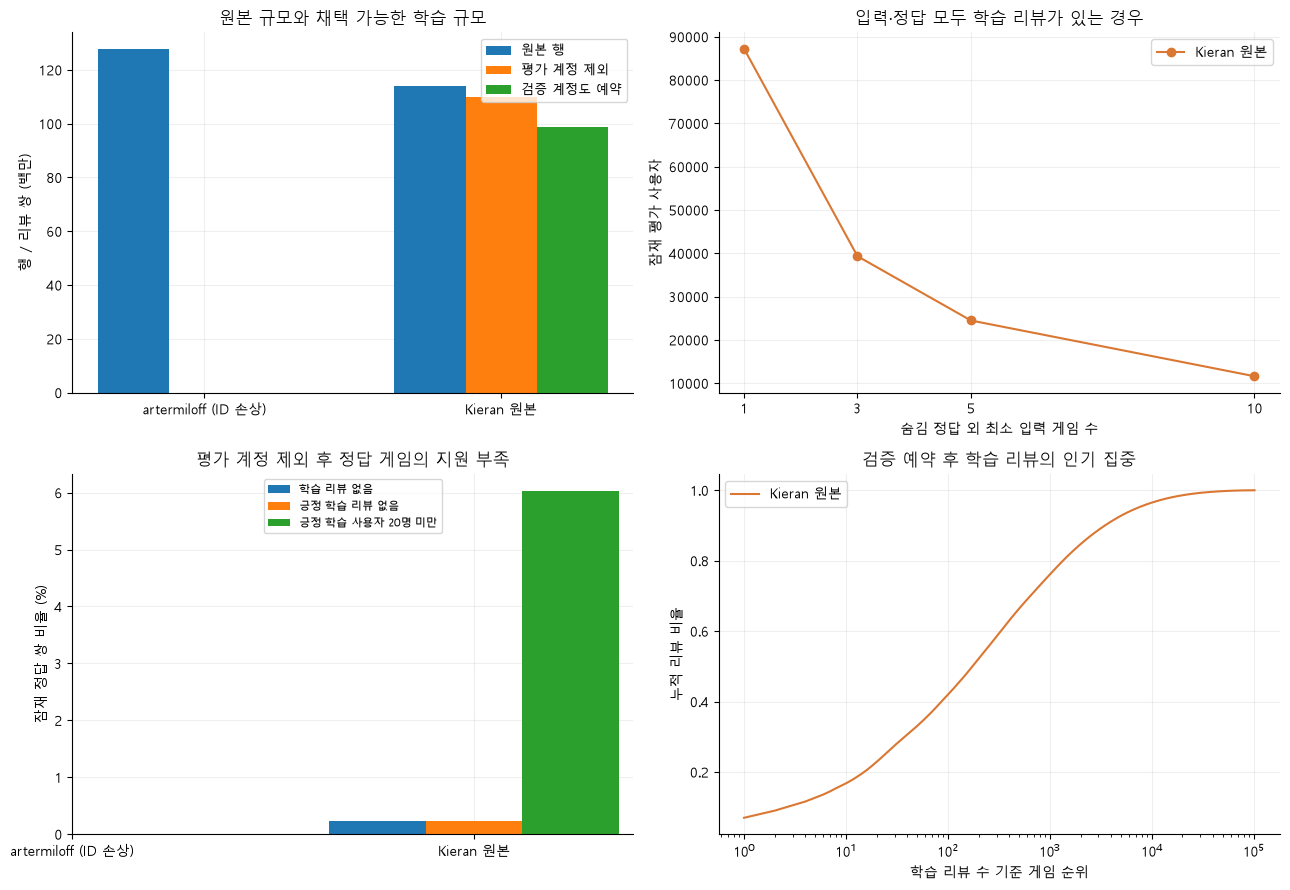

In [6]:
fig,axes=plt.subplots(2,2,figsize=(13,9))
x=np.arange(len(SOURCES))
for offset,(field,label) in enumerate([("clean_source","원본 행"),
                                      ("after_test_exclusion","평가 계정 제외"),
                                      ("after_validation_reservation","검증 계정도 예약")]):
    values=[(metrics[k]['raw_quality']['raw_rows'] if field=='clean_source' else metrics[k][field]['pairs'])/1e6
            if field=='clean_source' or metrics[k]['whole_account_and_cross_review_identity_checks_passed'] else np.nan for k in SOURCES]
    axes[0,0].bar(x+(offset-1)*.24,values,width=.24,label=label)
axes[0,0].set(xticks=x,xticklabels=list(SOURCES.values()),ylabel="행 / 리뷰 쌍 (백만)",title="원본 규모와 채택 가능한 학습 규모")
axes[0,0].legend(fontsize=9)
for (key,label),color in zip(SOURCES.items(),COLORS):
    m=metrics[key]
    if not m['whole_account_and_cross_review_identity_checks_passed']:
        continue
    rows=m["supported_cohort_sizes"]["any_review_support"]["after_validation_reservation"]
    axes[0,1].plot([r["minimum_inputs"] for r in rows],[r["potential_users"] for r in rows],marker="o",label=label,color=color)
    apps=pd.read_csv(EDA/"reports/tables"/f"16_{key}_app_support.csv")
    values=apps.final_train_reviews.sort_values(ascending=False).to_numpy()
    values=values[values>0]
    axes[1,1].plot(np.arange(1,len(values)+1),np.cumsum(values)/values.sum(),label=label,color=color)
axes[0,1].set(xticks=[1,3,5,10],xlabel="숨김 정답 외 최소 입력 게임 수",ylabel="잠재 평가 사용자",title="입력·정답 모두 학습 리뷰가 있는 경우")
axes[0,1].legend()
coverage=[metrics[k]["heldout_target_item_support"] for k in SOURCES]
for offset,(field,label) in enumerate([("targets_without_training_reviews","학습 리뷰 없음"),
                                      ("targets_without_positive_training_reviews","긍정 학습 리뷰 없음"),
                                      ("targets_with_fewer_than_20_positive_training_users","긍정 학습 사용자 20명 미만")]):
    axes[1,0].bar(x+(offset-1)*.24,[r[field]/r["possible_target_pairs"]*100 if metrics[k]['whole_account_and_cross_review_identity_checks_passed'] else np.nan for k,r in zip(SOURCES,coverage)],width=.24,label=label)
axes[1,0].set(xticks=x,xticklabels=list(SOURCES.values()),ylabel="잠재 정답 쌍 비율 (%)",title="평가 계정 제외 후 정답 게임의 지원 부족")
axes[1,0].legend(fontsize=8)
axes[1,1].set(xscale="log",xlabel="학습 리뷰 수 기준 게임 순위",ylabel="누적 리뷰 비율",title="검증 예약 후 학습 리뷰의 인기 집중")
axes[1,1].legend()
fig.tight_layout()
fig.savefig(EDA/"figures/fig13_large_original_frank_comparison.png",dpi=160,bbox_inches="tight")
plt.show()

## A+C 설명·태그 연결 범위

C의 태그는 비어 있지 않은 직렬화 값의 존재를 세었다. 최종 토큰 정제나
설명의 품질 인증을 의미하지 않는다. C의 평판·인기도 집계는 학습하지 않았다.

In [7]:
content=[]
for key,label in SOURCES.items():
    if not metrics[key]['whole_account_and_cross_review_identity_checks_passed']:
        continue
    c=metrics[key]["metadata_coverage"]
    total=metrics[key]["after_validation_reservation"]["pairs"]
    content.append({"학습 후보":label,"A+C 메타데이터 밖 게임":c["source_apps_without_A_or_C_metadata"],
                    "C에만 메타데이터가 있는 게임":c["C_only_source_apps"],
                    "설명 미연결 학습 리뷰 비율":(c["final_train_pairs_without_description"] or 0)/total,
                    "태그 미연결 학습 리뷰 비율":(c["final_train_pairs_without_tags"] or 0)/total})
display(pd.DataFrame(content))

,학습 후보,A+C 메타데이터 밖 게임,C에만 메타데이터가 있는 게임,설명 미연결 학습 리뷰 비율,태그 미연결 학습 리뷰 비율
0,Kieran 원본,28867,27164,0.056027,0.055556


## 4. 리뷰 작성 시기

배포 갱신일은 모든 리뷰의 수집 시각을 뜻하지 않는다.
동일 계정 제외는 신규 사용자 평가를 위한 절차이며, 시간순 미래 예측을
재현했다는 의미는 아니다. 이 그래프는 원본 행 기준이므로 중복도 포함한다.

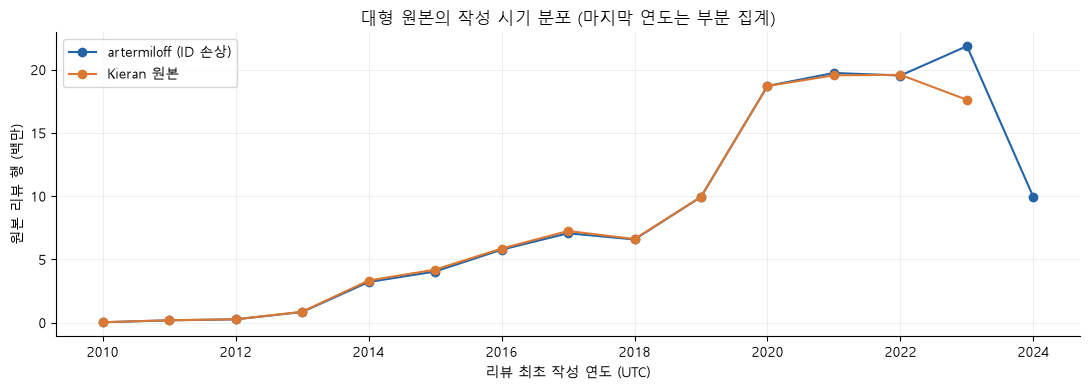

In [8]:
fig,ax=plt.subplots(figsize=(11,4))
for (key,label),color in zip(SOURCES.items(),COLORS):
    years=pd.DataFrame(metrics[key]["raw_created_years"])
    years=years[years.review_created_year.str.fullmatch(r"\d{4}")].copy()
    ax.plot(years.review_created_year.astype(int),years.raw_rows/1e6,marker="o",label=label,color=color)
ax.set(xlabel="리뷰 최초 작성 연도 (UTC)",ylabel="원본 리뷰 행 (백만)",title="대형 원본의 작성 시기 분포 (마지막 연도는 부분 집계)")
ax.legend()
fig.tight_layout()
fig.savefig(EDA/"figures/fig14_large_original_review_years.png",dpi=160,bbox_inches="tight")
plt.show()

## 재현

저장소 루트에서 `EDA/.venv/Scripts/python EDA/scripts/ingest_artermiloff_original.py`,
`EDA/.venv/Scripts/python EDA/scripts/ingest_kieran_original.py`로 원본을 준비한다.
이어서 `EDA/scripts/eda_large_review_frank.py artermiloff_2024`와
`EDA/scripts/eda_large_review_frank.py kieran_original`을 같은 Python으로 실행한다.
`EDA/scripts/compare_large_review_frank.py`로 공통·모호 리뷰 제거 평가 범위를 계산한다.
마지막으로 `EDA/.venv/Scripts/python EDA/scripts/build_notebook.py 03_large_review_train_test_eda`를 실행한다.
원본과 중간 사용자 데이터는 Git에 포함하지 않고 공개 결과는 집계만 저장한다.